In [ ]:
import kagglehub


path = kagglehub.dataset_download("ananthu017/emotion-detection-fer")

print("Path to dataset files:", path)


100%|██████████| 65.2M/65.2M [00:04<00:00, 14.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

1/
  test/
    happy/
      im1032.png
      im496.png
      im336.png
      im568.png
      im164.png
    disgusted/
      im69.png
      im52.png
      im25.png
      im65.png
      im55.png
    surprised/
      im496.png
      im336.png
      im568.png
      im164.png
      im185.png
    neutral/
      im1032.png
      im496.png
      im336.png
      im568.png
      im164.png
    sad/
      im1032.png
      im496.png
      im336.png
      im568.png
      im164.png
    angry/
      im496.png
      im336.png
      im568.png
      im164.png
      im185.png
    fearful/
      im496.png
      im336.png
      im568.png
      im164.png
      im185.png
  train/
    happy/
      im4274.png
      im3215.png
      im6453.png
      im6296.png
      im4102.png
    disgusted/
      im336.png
      im164.png
      im185.png
      im170.png
      im267.png
    surprised/
      im2030.png
      im2967.png
      im1032.png
      im2013.png
      im496.png
    neutral/
      im4274.png
      im3215.pn

In [ ]:
from collections import Counter
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in Path(path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images:", len(image_files))

folder_counts = Counter(p.parent.name for p in image_files)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

Total images: 35887
angry: 4953
disgusted: 547
fearful: 5121
happy: 8989
neutral: 6198
sad: 6077
surprised: 4002


In [ ]:
import cv2

In [ ]:
from pathlib import Path

dataset_path = Path(path)

for split in ["train", "test"]:
    split_path = dataset_path / split
    print(f"\n{split.upper()}")

    if not split_path.exists():
        print(f"{split} folder not found")
        continue

    for emotion_dir in sorted(split_path.iterdir()):
        if emotion_dir.is_dir():
            count = sum(
                1 for f in emotion_dir.iterdir()
                if f.suffix.lower() in {".png", ".jpg", ".jpeg"}
            )
            print(f"{emotion_dir.name}: {count}")


TRAIN
angry: 3995
disgusted: 436
fearful: 4097
happy: 7215
neutral: 4965
sad: 4830
surprised: 3171

TEST
angry: 958
disgusted: 111
fearful: 1024
happy: 1774
neutral: 1233
sad: 1247
surprised: 831


In [ ]:
%pip install opencv-python mediapipe matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.7/42.7 MB 45.8 MB/s  0:00:01
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]


In [ ]:
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

root = Path(path)
IMG, BATCH = 112, 128
AUTOTUNE = tf.data.AUTOTUNE

common = dict(color_mode="rgb",
              image_size=(IMG, IMG),
              label_mode="categorical",
              seed=42)

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "train"), validation_split=0.1, subset="training",
    batch_size=BATCH, **common)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "train"), validation_split=0.1, subset="validation",
    batch_size=BATCH, **common)
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "test"), shuffle=False, batch_size=BATCH,
    color_mode="rgb", image_size=(IMG, IMG), label_mode="categorical")

class_names = train_ds.class_names
print("Classes:", class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)


counts = np.array([len(list((root / "train" / c).glob("*"))) for c in class_names])
class_weight = {i: counts.sum() / (len(counts) * n) for i, n in enumerate(counts)}
print(dict(zip(class_names, counts)))
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
{'angry': np.int64(3995), 'disgusted': np.int64(436), 'fearful': np.int64(4097), 'happy': np.int64(7215), 'neutral': np.int64(4965), 'sad': np.int64(4830), 'surprised': np.int64(3171)}
{'angry': np.float64(1.03), 'disgusted': np.float64(9.41), 'fearful': np.float64(1.0), 'happy': np.float64(0.57), 'neutral': np.float64(0.83), 'sad': np.float64(0.85), 'surprised': np.float64(1.29)}


In [ ]:
from tensorflow.keras import layers, models

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
], name="augmentation")


base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False

inputs  = layers.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_emotion_model.keras",
        monitor="val_accuracy", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy",
        patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",
        factor=0.5, patience=2, verbose=1),
]


h1 = model.fit(train_ds, validation_data=val_ds, epochs=6,
               class_weight=class_weight, callbacks=callbacks)

base.trainable = True
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=20,
               class_weight=class_weight, callbacks=callbacks)

Epoch 1/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.2616 - loss: 1.8753
Epoch 1: val_accuracy improved from None to 0.41185, saving model to best_emotion_model.keras

Epoch 1: finished saving model to best_emotion_model.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 42s 132ms/step - accuracy: 0.3077 - loss: 1.7977 - val_accuracy: 0.4118 - val_loss: 1.6433 - learning_rate: 0.0010
Epoch 2/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.3727 - loss: 1.7007
Epoch 2: val_accuracy improved from 0.41185 to 0.43693, saving model to best_emotion_model.keras

Epoch 2: finished saving model to best_emotion_model.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 27s 96ms/step - accuracy: 0.3729 - loss: 1.6874 - val_accuracy: 0.4369 - val_loss: 1.5926 - learning_rate: 0.0010
Epoch 3/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.3970 - loss: 1.6476
Epoch 3: val_accuracy improved from 0.43693 to 0.45087, saving model to best_emotion_model.keras

Epoch 3: finished saving model to best_emotion

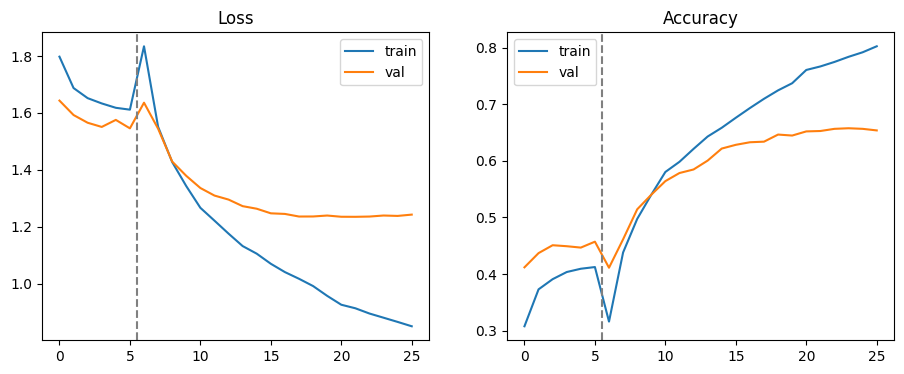

In [17]:
acc  = h1.history["accuracy"]     + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss  = h1.history["loss"]     + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(loss, label="train"); ax[0].plot(vloss, label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(acc, label="train");  ax[1].plot(vacc, label="val");  ax[1].set_title("Accuracy"); ax[1].legend()
for a in ax: a.axvline(len(h1.history["loss"]) - 0.5, ls="--", c="gray")  # phase boundary
plt.show()

57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 119ms/step
              precision    recall  f1-score   support

       angry      0.564     0.574     0.569       958
   disgusted      0.588     0.721     0.648       111
     fearful      0.560     0.409     0.473      1024
       happy      0.887     0.827     0.856      1774
     neutral      0.560     0.690     0.618      1233
         sad      0.543     0.564     0.553      1247
   surprised      0.772     0.789     0.780       831

    accuracy                          0.658      7178
   macro avg      0.639     0.653     0.642      7178
weighted avg      0.663     0.658     0.658      7178



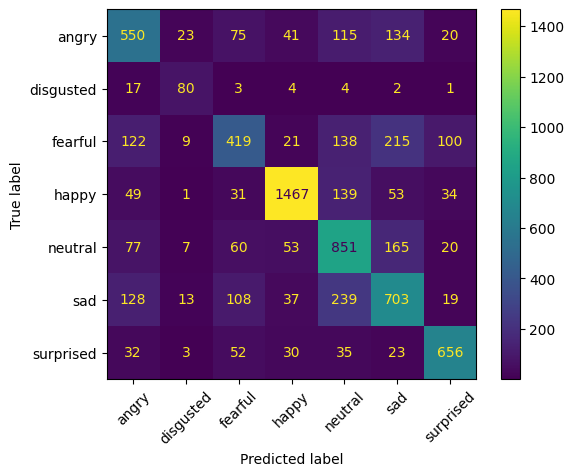

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model = tf.keras.models.load_model("best_emotion_model.keras")

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(xticks_rotation=45)
plt.show()

## Model 2: ResNet50 (for comparison with EfficientNetB0)
Same data, same augmentation, same two-phase training and same hyperparameters, so the only thing that changes is the backbone. Run all cells above first.

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

eff_model  = model
y_pred_eff = y_pred
eff_hist   = (h1.history, h2.history)
eff_params = eff_model.count_params()
print("EfficientNetB0 test accuracy:", round(accuracy_score(y_true, y_pred_eff), 4))

In [13]:
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess


res_base = tf.keras.applications.ResNet50(
    include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
res_base.trainable = False

r_in = layers.Input(shape=(IMG, IMG, 3))
r = augment(r_in)
r = layers.Lambda(resnet_preprocess, name="resnet_preprocess")(r)
r = res_base(r, training=False)
r = layers.GlobalAveragePooling2D()(r)
r = layers.Dropout(0.3)(r)
r_out = layers.Dense(len(class_names), activation="softmax")(r)
res_model = models.Model(r_in, r_out, name="resnet50_emotion")

res_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
res_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "resnet50_emotion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │        14,343 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,602,055 (90.03 MB)

 Trainable params: 14,343 (56.03 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [14]:
res_callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_resnet.weights.h5", monitor="val_accuracy",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]


r1 = res_model.fit(train_ds, validation_data=val_ds, epochs=6,
                   class_weight=class_weight, callbacks=res_callbacks)


res_base.trainable = True
res_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
r2 = res_model.fit(train_ds, validation_data=val_ds, epochs=20,
                   class_weight=class_weight, callbacks=res_callbacks)

Epoch 1/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.2586 - loss: 2.3732
Epoch 1: val_accuracy improved from None to 0.45226, saving model to best_resnet.weights.h5

Epoch 1: finished saving model to best_resnet.weights.h5
202/202 ━━━━━━━━━━━━━━━━━━━━ 47s 198ms/step - accuracy: 0.3056 - loss: 2.0821 - val_accuracy: 0.4523 - val_loss: 1.5680 - learning_rate: 0.0010
Epoch 2/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.3828 - loss: 1.7558
Epoch 2: val_accuracy improved from 0.45226 to 0.46307, saving model to best_resnet.weights.h5

Epoch 2: finished saving model to best_resnet.weights.h5
202/202 ━━━━━━━━━━━━━━━━━━━━ 36s 178ms/step - accuracy: 0.3878 - loss: 1.7363 - val_accuracy: 0.4631 - val_loss: 1.5643 - learning_rate: 0.0010
Epoch 3/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.4123 - loss: 1.6523
Epoch 3: val_accuracy improved from 0.46307 to 0.48118, saving model to best_resnet.weights.h5

Epoch 3: finished saving model to best_resnet.weight

57/57 ━━━━━━━━━━━━━━━━━━━━ 12s 178ms/step
              precision    recall  f1-score   support

       angry      0.618     0.575     0.596       958
   disgusted      0.680     0.748     0.712       111
     fearful      0.628     0.458     0.530      1024
       happy      0.856     0.857     0.857      1774
     neutral      0.588     0.683     0.632      1233
         sad      0.542     0.597     0.568      1247
   surprised      0.802     0.809     0.805       831

    accuracy                          0.680      7178
   macro avg      0.674     0.675     0.672      7178
weighted avg      0.682     0.680     0.678      7178



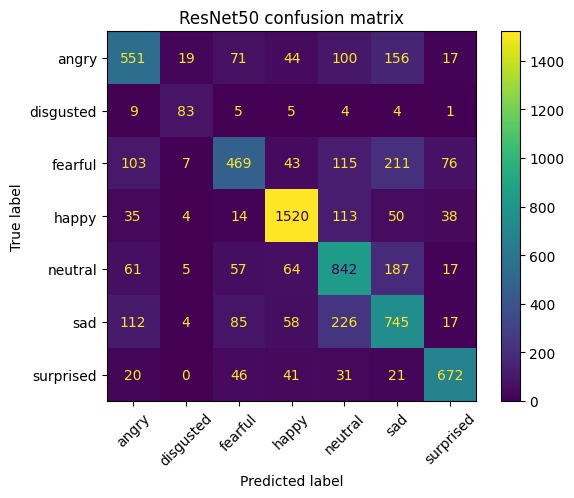

In [15]:

res_model.load_weights("best_resnet.weights.h5")
y_pred_res = np.argmax(res_model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred_res, target_names=class_names, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred_res),
                       display_labels=class_names).plot(xticks_rotation=45)
plt.title("ResNet50 confusion matrix")
plt.show()

,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1,Parameters (M),Best val acc
EfficientNetB0,0.658,0.639,0.653,0.642,0.658,4.1,0.657
ResNet50,0.680,0.674,0.675,0.672,0.678,23.6,0.662


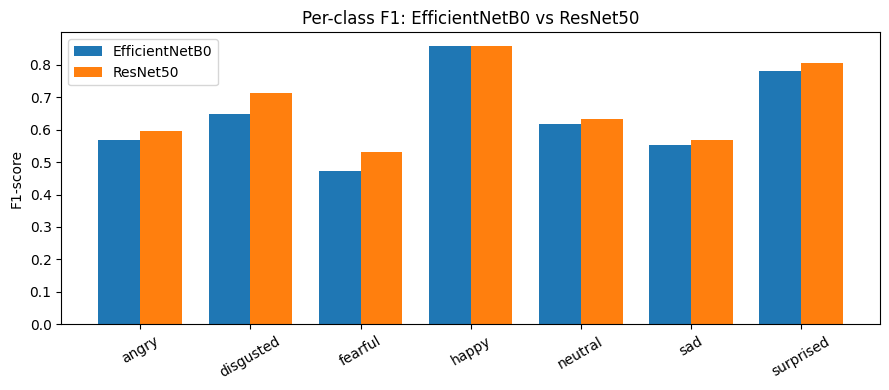

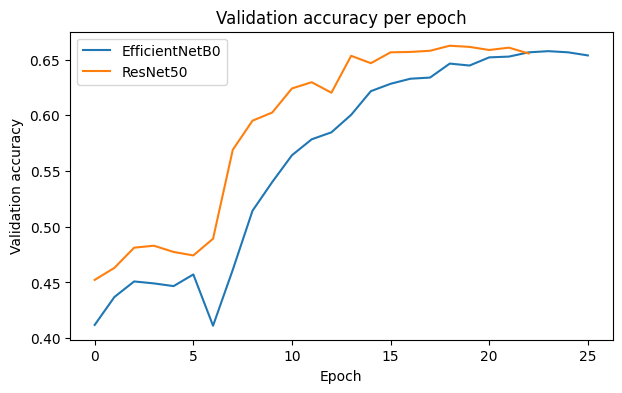

In [16]:
import pandas as pd

def summary(y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return [accuracy_score(y_true, y_pred), p, r, f, fw]

cmp = pd.DataFrame(
    [summary(y_pred_eff), summary(y_pred_res)],
    index=["EfficientNetB0", "ResNet50"],
    columns=["Accuracy", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"]).round(3)
cmp["Parameters (M)"] = [round(eff_params/1e6, 1), round(res_model.count_params()/1e6, 1)]
cmp["Best val acc"] = [round(max(eff_hist[0]["val_accuracy"] + eff_hist[1]["val_accuracy"]), 3),
                       round(max(r1.history["val_accuracy"] + r2.history["val_accuracy"]), 3)]
display(cmp)

f1_eff = precision_recall_fscore_support(y_true, y_pred_eff, zero_division=0)[2]
f1_res = precision_recall_fscore_support(y_true, y_pred_res, zero_division=0)[2]
x = np.arange(len(class_names)); w = 0.38
plt.figure(figsize=(9, 4))
plt.bar(x - w/2, f1_eff, w, label="EfficientNetB0")
plt.bar(x + w/2, f1_res, w, label="ResNet50")
plt.xticks(x, class_names, rotation=30); plt.ylabel("F1-score")
plt.title("Per-class F1: EfficientNetB0 vs ResNet50"); plt.legend(); plt.tight_layout(); plt.show()


plt.figure(figsize=(7, 4))
plt.plot(eff_hist[0]["val_accuracy"] + eff_hist[1]["val_accuracy"], label="EfficientNetB0")
plt.plot(r1.history["val_accuracy"] + r2.history["val_accuracy"], label="ResNet50")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.title("Validation accuracy per epoch")
plt.legend(); plt.show()